In [1]:
import utils
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

In [3]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df.select_dtypes(include="number"))

In [7]:
from sklearn.decomposition import PCA

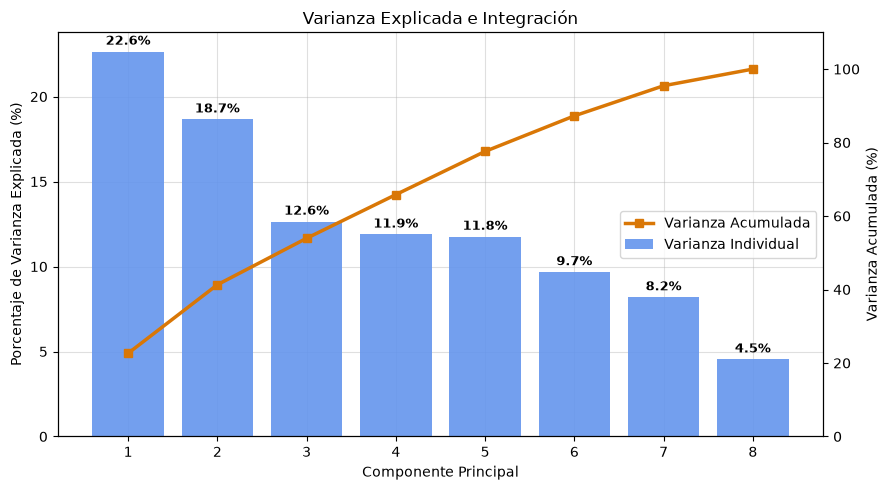

In [8]:
# Ajustar PCA con todas las componentes
pca = PCA()
pca.fit_transform(df_scaled)

# Calcular porcentajes
varianza_individual = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza_individual)

componentes = np.arange(1, len(varianza_individual) + 1)

# Crear gráfico
fig, ax1 = plt.subplots(figsize=(9, 5))

# Barras: varianza individual
ax1.bar(
    componentes,
    varianza_individual,
    color="cornflowerblue",
    alpha=0.9,
    label="Varianza Individual"
)

ax1.set_xlabel("Componente Principal")
ax1.set_ylabel("Porcentaje de Varianza Explicada (%)")
ax1.set_xticks(componentes)
ax1.set_title("Varianza Explicada e Integración")
ax1.grid(axis="both", alpha=0.4)
ax1.set_axisbelow(True)

# Etiquetas sobre las barras
for x, y in zip(componentes, varianza_individual):
    ax1.annotate(
        f"{y:.1f}%",
        (x, y),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Línea: varianza acumulada
ax2 = ax1.twinx()
ax2.plot(
    componentes,
    varianza_acumulada,
    color="#d97706",
    marker="s",
    linewidth=2.5,
    label="Varianza Acumulada"
)

ax2.set_ylabel("Varianza Acumulada (%)")
ax2.set_ylim(0, 110)

# Leyenda combinada
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles2 + handles1,
    labels2 + labels1,
    loc="center right"
)

plt.tight_layout()
plt.show()

Asi, se necesita de 7 componentes para obtener un 95% de la varianza total acumulada

In [15]:
pca = PCA(n_components=7, whiten=False)
principalComponents = pca.fit_transform(df_scaled)

In [16]:
print(pca.explained_variance_ratio_.sum())

0.9546297400824355
